--- Variância Explicada por Componente ---
PC1: 54.21%
PC2: 20.40%
Total explicado: 74.61%



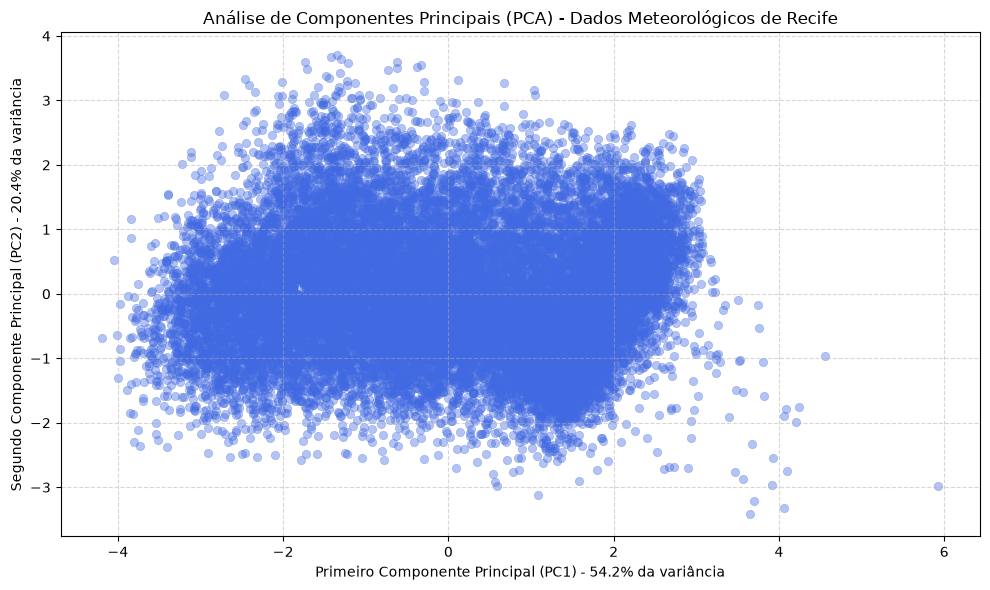

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

colunas_pca = [
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)'
]

df_pca = df[colunas_pca].dropna().copy()

df_pca.columns = ['Precipitacao', 'Pressao', 'Temperatura', 'Umidade', 'Vento']

scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(df_pca)

pca = PCA(n_components=2)
componentes_principais = pca.fit_transform(dados_padronizados)

df_pca_resultado = pd.DataFrame(
    data=componentes_principais, 
    columns=['PC1', 'PC2']
)

print("--- Variância Explicada por Componente ---")
print(f"PC1: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Total explicado: {sum(pca.explained_variance_ratio_)*100:.2f}%\n")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_pca_resultado,
    x='PC1',
    y='PC2',
    alpha=0.4,
    color='royalblue',
    edgecolor=None
)

plt.title('Análise de Componentes Principais (PCA) - Dados Meteorológicos de Recife')
plt.xlabel(f'Primeiro Componente Principal (PC1) - {pca.explained_variance_ratio_[0]*100:.1f}% da variância')
plt.ylabel(f'Segundo Componente Principal (PC2) - {pca.explained_variance_ratio_[1]*100:.1f}% da variância')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

--- Variância Explicada ---
PC1: 54.21%
PC2: 20.40%
Total acumulado: 74.61%

--- Pesos (Loadings) das Variáveis nos Componentes ---


,PC1,PC2
Precipitação,0.144792,-0.079871
Pressão,0.178274,0.937318
Temperatura,-0.574373,-0.102549
Umidade,0.580765,-0.084961
Vento,-0.529208,0.311964


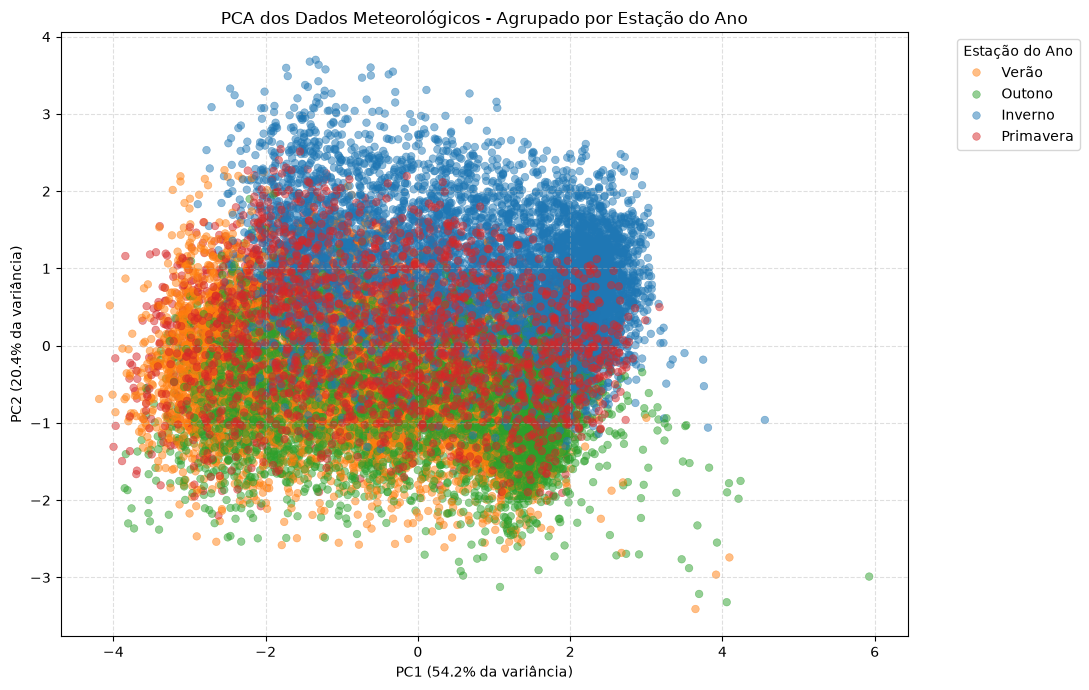

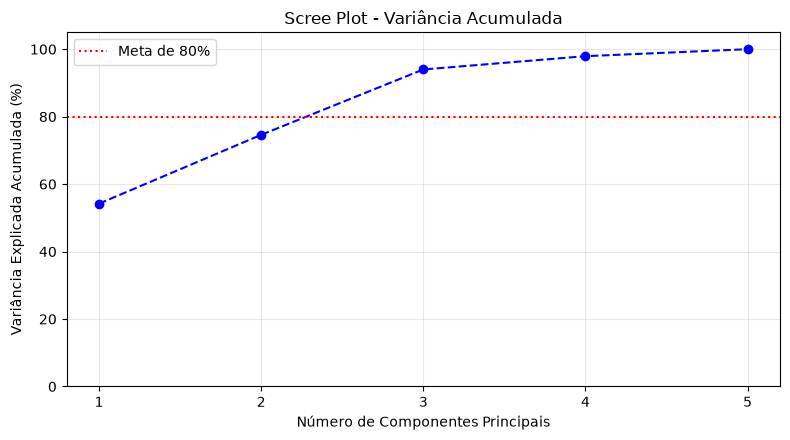

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Carregar e preparar os dados
df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

colunas_pca = [
    'datetime',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)'
]

df_pca = df[colunas_pca].dropna().copy()
df_pca['datetime'] = pd.to_datetime(df_pca['datetime'])
df_pca['mes'] = df_pca['datetime'].dt.month

# Classificar estações do ano
estacoes = {
    12: 'Verão', 1: 'Verão', 2: 'Verão',
    3: 'Outono', 4: 'Outono', 5: 'Outono',
    6: 'Inverno', 7: 'Inverno', 8: 'Inverno',
    9: 'Primavera', 10: 'Primavera', 11: 'Primavera'
}
df_pca['estacao'] = df_pca['mes'].map(estacoes)

# 2. Selecionar recursos e padronizar
features = [
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)'
]
nomes_amigaveis = ['Precipitação', 'Pressão', 'Temperatura', 'Umidade', 'Vento']

X = df_pca[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Aplicar PCA (extraindo 2 componentes principais)
pca = PCA(n_components=2)
PCs = pca.fit_transform(X_scaled)

df_pca['PC1'] = PCs[:, 0]
df_pca['PC2'] = PCs[:, 1]

# Exibir variância explicada
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
print(f"--- Variância Explicada ---")
print(f"PC1: {var_pc1:.2f}%")
print(f"PC2: {var_pc2:.2f}%")
print(f"Total acumulado: {var_pc1 + var_pc2:.2f}%\n")

# 4. Calcular e exibir as Cargas (Loadings / Pesos das variáveis)
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=nomes_amigaveis
)
print("--- Pesos (Loadings) das Variáveis nos Componentes ---")
display(loadings)

# 5. Gráfico 1: Dispersão colorido por Estação do Ano
plt.figure(figsize=(11, 7))
ordem_estacoes = ['Verão', 'Outono', 'Inverno', 'Primavera']
palette = {'Verão': '#ff7f0e', 'Outono': '#2ca02c', 'Inverno': '#1f77b4', 'Primavera': '#d62728'}

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='estacao',
    hue_order=ordem_estacoes,
    palette=palette,
    alpha=0.5,
    s=30,
    edgecolor=None
)

plt.title('PCA dos Dados Meteorológicos - Agrupado por Estação do Ano')
plt.xlabel(f'PC1 ({var_pc1:.1f}% da variância)')
plt.ylabel(f'PC2 ({var_pc2:.1f}% da variância)')
plt.legend(title='Estação do Ano', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 6. Gráfico 2: Scree Plot (Variância Acumulada de todos os componentes)
pca_full = PCA().fit(X_scaled)
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         np.cumsum(pca_full.explained_variance_ratio_) * 100, 
         marker='o', linestyle='--', color='b')
plt.title('Scree Plot - Variância Acumulada')
plt.xlabel('Número de Componentes Principais')
plt.ylabel('Variância Explicada Acumulada (%)')
plt.xticks(range(1, len(features) + 1))
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.axhline(y=80, color='r', linestyle=':', label='Meta de 80%')
plt.legend()
plt.tight_layout()
plt.show()

Variância explicada:
PC1: 54.21%
PC2: 20.40%
PC3: 19.39%
PC4: 3.94%
PC5: 2.07%

Variância acumulada nos 2 primeiros componentes: 74.61%


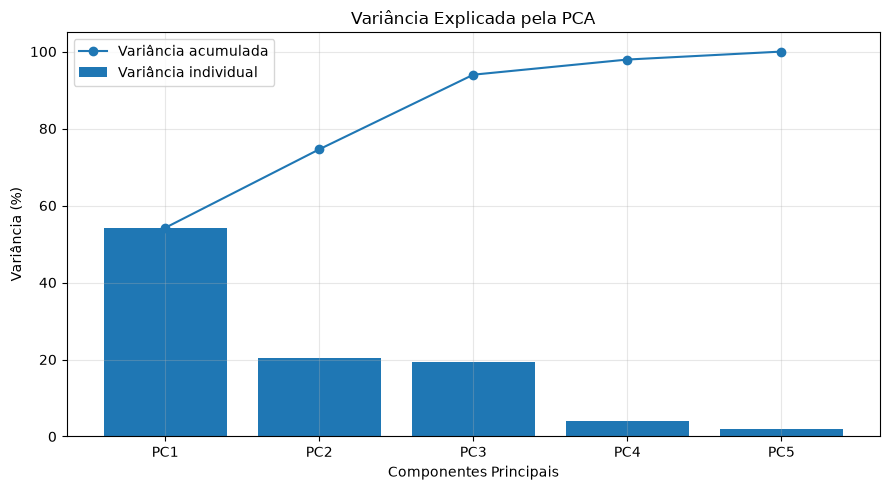

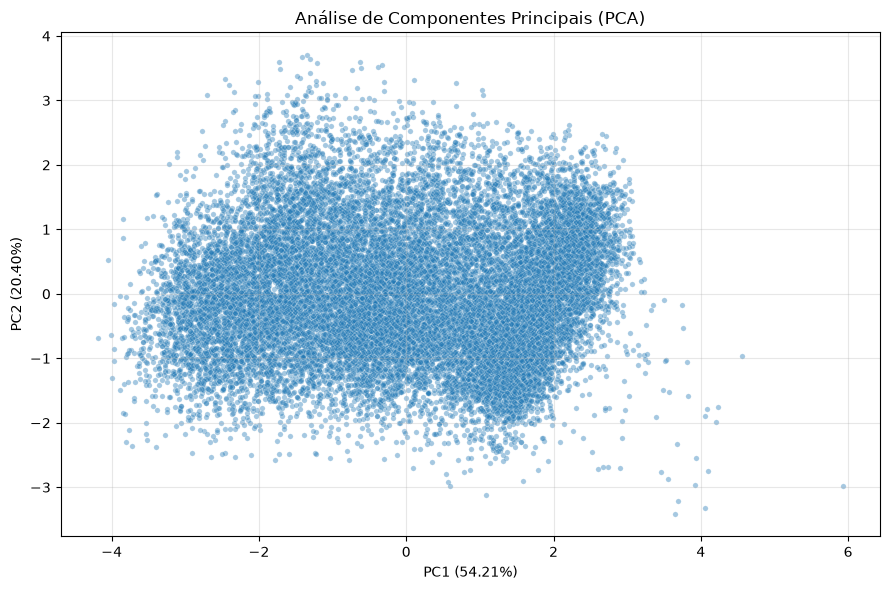


Contribuição das variáveis:
                                                      PC1    PC2
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       -0.574 -0.103
UMIDADE RELATIVA DO AR, HORARIA (%)                 0.581 -0.085
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI...  0.178  0.937
VENTO, VELOCIDADE HORARIA (m/s)                    -0.529  0.312
PRECIPITAÇÃO TOTAL, HORÁRIO (mm)                    0.145 -0.080


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Carregar os dados
df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

# 2. Selecionar variáveis numéricas
variaveis = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
]

dados = df[variaveis].copy()

# 3. Limpar e converter os dados
dados = dados.apply(pd.to_numeric, errors='coerce')
dados = dados.dropna()

# 4. Padronizar os dados
scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(dados)

# 5. Aplicar PCA
pca = PCA()
componentes = pca.fit_transform(dados_padronizados)

# 6. Variância explicada
variancia = pca.explained_variance_ratio_ * 100
variancia_acumulada = variancia.cumsum()

print('Variância explicada:')
for i, valor in enumerate(variancia):
    print(f'PC{i+1}: {valor:.2f}%')

print(f'\nVariância acumulada nos 2 primeiros componentes: {variancia_acumulada[1]:.2f}%')

# 7. Gráfico da variância explicada
plt.figure(figsize=(9, 5))

plt.bar(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia,
    label='Variância individual'
)

plt.plot(
    [f'PC{i+1}' for i in range(len(variancia))],
    variancia_acumulada,
    marker='o',
    label='Variância acumulada'
)

plt.title('Variância Explicada pela PCA')
plt.xlabel('Componentes Principais')
plt.ylabel('Variância (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Gráfico dos dois primeiros componentes
df_pca = pd.DataFrame(
    componentes[:, :2],
    columns=['PC1', 'PC2']
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    alpha=0.4,
    s=15
)

plt.title('Análise de Componentes Principais (PCA)')
plt.xlabel(f'PC1 ({variancia[0]:.2f}%)')
plt.ylabel(f'PC2 ({variancia[1]:.2f}%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 9. Contribuição das variáveis
contribuicoes = pd.DataFrame(
    pca.components_[:2].T,
    index=variaveis,
    columns=['PC1', 'PC2']
)

print('\nContribuição das variáveis:')
print(contribuicoes.round(3))


## Resultados da Análise de Componentes Principais (PCA)

A aplicação da PCA sobre as variáveis meteorológicas (Temperatura, Umidade, Pressão, Vento e Precipitação) permitiu resumir a multidimensionalidade dos dados em eixos sintéticos principais, cujos resultados são detalhados abaixo:

Variância Explicada e Acumulada (Scree Plot):
  * O primeiro componente principal isoladamente é responsável por reter 54,21% da variância total dos dados.
  * O segundo componente PC2 explica cerca de 20,40%.
  * Juntos, PC1 e PC2 acumulam aproximadamente 74,61% de toda a informação contida nas cinco variáveis originais.
  * Nota-se também que os três primeiros componentes (PC1, PC2 e PC3) ultrapassam a marca de 90% de variância acumulada.

Distribuição Fatorial (Scatter Plot de PC1 vs PC2):
  * O gráfico de dispersão dos pontos no espaço formado por PC1 e PC2 demonstra uma grande densidade de registros concentrada próxima à região central (valores entre -2 e 2 nos eixos).
  * A forma da nuvem de pontos revela um comportamento contínuo das condições meteorológicas horárias, com alguns *outliers* (pontos mais isolados à direita e na parte inferior), correspondendo a momentos de registros atípicos ou eventos extremos de vento/precipitação na série histórica.